# PENGWIN, semana 11: sobreajuste de la cabeza de borde

Proyecto Integrador Corte 2, Analítica de Datos, UAO 2026-2. Uso exclusivamente académico.

La cabeza de borde sobreajusta, y es la causa de fondo del Dice por fragmento (`03_semana11` §10.2). Esta semana se probaron tres remedios que faltaban, con reglas escritas antes de entrenar (`reports/tuning/s11_borde/PREREGISTRO.md`). Las corridas se hicieron en ANTON (`scripts/s11_borde/orquestar.sh`); aquí solo se leen sus resultados.

1. Qué preguntamos
2. Curvas de pérdida del borde
3. Cribado
4. Confirmación
5. Modelo final y test
6. Lectura y decisión

Como los demás notebooks, lee lo guardado en `reports/` y no necesita GPU.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)


def find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "03_src" / "pengwin").is_dir():
            return p
    raise FileNotFoundError("No se encontró la raíz del repositorio")


ROOT = find_root()
REP = ROOT / "reports"
SB = REP / "tuning" / "s11_borde"
FIG = REP / "figures" / "semana11"
FIG.mkdir(parents=True, exist_ok=True)

C = {"SA": "#2a78d6", "LI": "#eb6834", "RI": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2,
})


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")


def read_json(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def run(k):
    return f"s11_{k.removeprefix('s11_')}_e12_f0"


CAND = ["c11_wd1e2", "c12_segw32", "c13_unetpp"]
CORR = {"s11_ref": "s11_ref (control)", "c11_wd1e2": "c11 · L2 ×100", "c12_segw32": "c12 · decodificador 32 canales",
        "c13_unetpp": "c13 · U-Net++"}
COL = {"s11_ref": INK2, "c11_wd1e2": C["SA"], "c12_segw32": C["RI"], "c13_unetpp": C["LI"]}
E1 = read_json(SB / "etapa1.json")
E2 = read_json(SB / "etapa2.json")
ETAPA = (SB / "ETAPA").read_text(encoding="utf-8").strip()
print("ETAPA:", ETAPA, "· etapa2.json:", "sí" if E2 else "no")

ETAPA: terminado (confirmar: ninguno · ganador: ninguno) · etapa2.json: no


## 1. Qué preguntamos

En `v2_repro` la BCE del borde en train baja de 0,064 a 0,005 en 40 épocas, y la de validación sube de 0,018 a 0,034. Train baja y validación sube: sobreajuste.

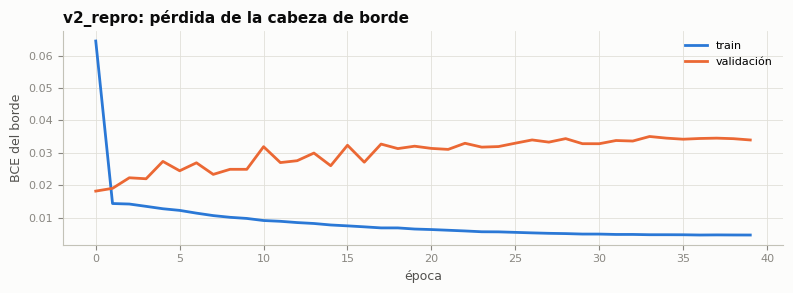

train 0.064 → 0.005 · validación 0.018 → 0.034 (mínimo 0.018 en la época 0)


In [2]:
h = pd.read_csv(REP / "train" / "v2_repro_history.csv")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(h.epoch, h.train_edge_bce, color=C["SA"], label="train")
ax.plot(h.epoch, h.val_edge_bce, color=C["LI"], label="validación")
ax.set(xlabel="época", ylabel="BCE del borde")
ax.set_title("v2_repro: pérdida de la cabeza de borde", loc="left")
ax.legend()
fig.tight_layout()
savefig(fig, "v2_repro_borde")
plt.show()
print(f"train {h.train_edge_bce.iloc[0]:.3f} → {h.train_edge_bce.iloc[-1]:.3f} · "
      f"validación {h.val_edge_bce.iloc[0]:.3f} → {h.val_edge_bce.iloc[-1]:.3f} (mínimo {h.val_edge_bce.min():.3f} en la época {h.val_edge_bce.idxmin()})")

Lo que ya estaba probado (no se repite):

| Remedio | Dónde | Resultado |
|---|---|---|
| Congelar el backbone | `ftseg`, semana 11 | empeora: −0,015, t = −5,2, 0/5 folds |
| Frenar el backbone (lr × 0,3) | `c10` | empeora 4,3σ |
| Aumentación fuerte | `c09` | subajusta |
| Dropout espacial 0-0,40 | `c07`, `c08`, `sd025-040` | sin efecto |
| Tasa de aprendizaje 1e-3 | `c06` | sin efecto |
| Otras representaciones del borde | `core3`, `dist` | peores |

Lo que faltaba, y se probó (lo demás es `c00_base`):

| Candidato | Cambio | Pregunta |
|---|---|---|
| `c11_wd1e2` | `weight_decay` 1e-4 → 1e-2 | ¿L2 cierra la brecha? |
| `c12_segw32` | decodificador de segmentación de 64 a 32 canales (−55 % de parámetros) | ¿reducir el modelo donde sobreajusta? |
| `c13_unetpp` | decodificador U-Net++: C0 a resolución completa, skips anidadas, supervisión profunda (Zhou et al., 2018) | ¿le faltaba detalle fino? |

Reglas: cribado en el fold 0 con 12 épocas contra cinco referencias de la configuración base; pasa quien tenga Dice por fragmento ≥ μ + 2σ **y** IoU por fragmento ≥ la media de las referencias. Luego, confirmación en 5 folds y, solo si hay ganador, modelo final y una medición de test.

In [3]:
par = {k: read_json(SB / "historiales" / f"{run(k)}.json")["parametros"] for k in CORR}
display(pd.DataFrame({CORR[k]: {"cabeza de segmentación": v["seg_head"], "total": v["total"]} for k, v in par.items()}).T)

,cabeza de segmentación,total
s11_ref (control),147877,2921886
c11 · L2 ×100,147877,2921886
c12 · decodificador 32 canales,67029,2841038
c13 · U-Net++,342383,3116392


## 2. Curvas de pérdida del borde, train contra validación

Fold 0, 12 épocas. Se usan las columnas `*_edge_*`, que siempre son de la salida final; en `c13_unetpp`, `train_seg` promedia la supervisión profunda y no es comparable.

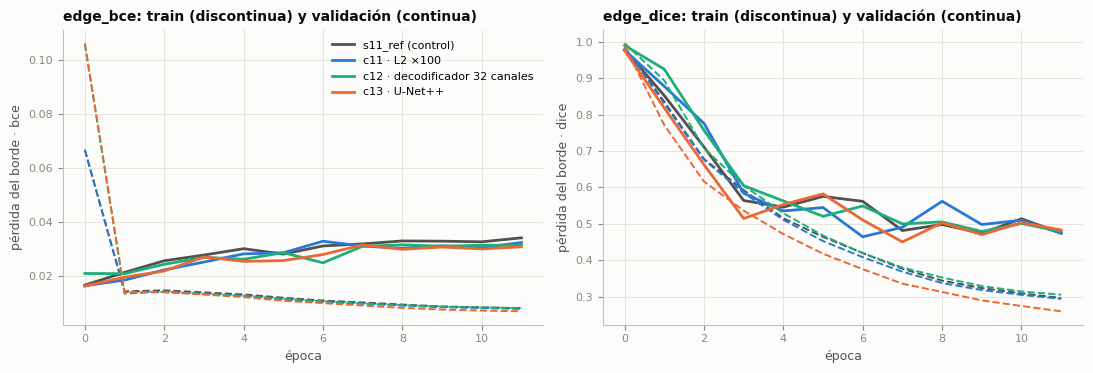

,train BCE final,val BCE final,val BCE mínima,época del mínimo,brecha BCE (val − train),train Dice-loss final,val Dice-loss final,mAP@[.50:.95],épocas,NaN
s11_ref (control),0.0080,0.0341,0.0165,0.0,0.0261,0.2965,0.4745,0.8244,12.0,0.0
c11 · L2 ×100,0.0077,0.0323,0.0163,0.0,0.0246,0.2939,0.4741,0.8281,12.0,0.0
c12 · decodificador 32 canales,0.0080,0.0314,0.0208,1.0,0.0234,0.3055,0.4790,0.8260,12.0,0.0
c13 · U-Net++,0.0068,0.0307,0.0162,0.0,0.0239,0.2598,0.4833,0.8183,12.0,0.0


In [4]:
H = {k: pd.read_csv(SB / "historiales" / f"{run(k)}_history.csv") for k in CORR}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m in zip(axes, ("edge_bce", "edge_dice")):
    for k, d in H.items():
        ax.plot(d.epoch, d[f"train_{m}"], color=COL[k], ls="--", lw=1.4)
        ax.plot(d.epoch, d[f"val_{m}"], color=COL[k], label=CORR[k])
    ax.set(xlabel="época", ylabel=m.replace("edge_", "pérdida del borde · "))
    ax.set_title(f"{m}: train (discontinua) y validación (continua)", loc="left", fontsize=10)
axes[0].legend()
fig.tight_layout()
savefig(fig, "curvas_borde")
plt.show()

filas = {}
for k, d in H.items():
    filas[CORR[k]] = {"train BCE final": d.train_edge_bce.iloc[-1], "val BCE final": d.val_edge_bce.iloc[-1],
                      "val BCE mínima": d.val_edge_bce.min(), "época del mínimo": int(d.val_edge_bce.idxmin()),
                      "brecha BCE (val − train)": d.val_edge_bce.iloc[-1] - d.train_edge_bce.iloc[-1],
                      "train Dice-loss final": d.train_edge_dice.iloc[-1], "val Dice-loss final": d.val_edge_dice.iloc[-1],
                      "mAP@[.50:.95]": d["mAP@[.50:.95]"].iloc[-1], "épocas": len(d), "NaN": int(d.isna().sum().sum())}
display(pd.DataFrame(filas).T)

- **Los cuatro sobreajustan igual.** La BCE de validación tiene su mínimo en la época 0 o 1 y sube hasta ~0,031-0,034, mientras la de train baja a ~0,007-0,008. Ninguno de los tres cambios cierra la brecha: la reduce como mucho en 0,003, que en una corrida de un fold es ruido.
- L2 ×100 (`c11`) deja las curvas casi encima de las del control: con AdamW el decaimiento desacoplado de 1e-2 sigue siendo poco frente a 12 épocas de gradiente.
- Ninguna corrida falló en silencio: 12 épocas, sin NaN, mAP@[.50:.95] en 0,818-0,828. `c13_unetpp` tardó más por época (~1 200 s) mientras corrían los otros tres carriles y bajó a ~365 s cuando quedó sola; es reparto de la GPU, no un error.

## 3. Cribado

Para cada corrida, la mejor combinación de la misma grilla de posproceso (`edt`, profundidad 1,5-6 mm × umbral 0,1-0,5, sin TTA). Aquí se recalcula desde los CSV crudos, sin usar las cifras de `etapa1.json`, y se comparan al final.

In [5]:
def mejor_csv(p):
    d = pd.read_csv(p)
    return d.loc[d.dice_fragmento.idxmax()]


def mejor_json(p):
    d = pd.DataFrame(read_json(p)["ranking"])
    return d.loc[d.dice_fragmento_media.idxmax()].rename({c: c.replace("_media", "") for c in d.columns})


ref = {}
for p in sorted((SB / "referencia").glob("pp_scr_cv_*_e12_f0.json")):
    ref[p.stem.replace("pp_scr_", "")] = mejor_json(p)
ref["s11_ref_e12_f0"] = mejor_csv(SB / "resultados" / "pp_scr_s11_ref_e12_f0.csv")
cols = ["dice_fragmento", "iou_fragmento", "dice_principal", "dice_secundario", "recuperados_secundarios_%", "seed_depth_mm", "edge_threshold"]
R = pd.DataFrame(ref).T[cols].astype(float)
mu, sd, iou_ref = R.dice_fragmento.mean(), R.dice_fragmento.std(ddof=1), R.iou_fragmento.mean()
umbral = mu + 2 * sd
f1 = R.dice_fragmento.iloc[:4]
display(R)
print(f"Referencia: μ = {mu:.4f} · σ = {sd:.4f} · umbral μ + 2σ = {umbral:.4f} · IoU medio = {iou_ref:.4f}")
print(f"Control s11_ref frente a las 4 de la Fase 1 (μ {f1.mean():.4f}, σ {f1.std():.4f}): z = {(R.dice_fragmento.iloc[-1] - f1.mean()) / f1.std():+.2f}")

,dice_fragmento,iou_fragmento,dice_principal,dice_secundario,recuperados_secundarios_%,seed_depth_mm,edge_threshold
cv_c00_base_e12_f0,0.6925,0.6296,0.9225,0.4792,47.2727,4.0,0.3
cv_c00b_seed1337_e12_f0,0.6700,0.5914,0.8871,0.4687,45.4545,6.0,0.2
cv_c00c_seed2024_e12_f0,0.6770,0.6052,0.8939,0.4759,50.9091,6.0,0.5
cv_c00c_seed7_e12_f0,0.6746,0.5981,0.8893,0.4756,45.4545,6.0,0.1
s11_ref_e12_f0,0.6819,0.6193,0.9214,0.4599,45.4545,4.0,0.2


Referencia: μ = 0.6792 · σ = 0.0086 · umbral μ + 2σ = 0.6964 · IoU medio = 0.6087
Control s11_ref frente a las 4 de la Fase 1 (μ 0.6785, σ 0.0097): z = +0.35


El control `s11_ref` (mismo código y semilla que `c00_base`, con el código nuevo de la semana 11) cae dentro de las cuatro referencias de la Fase 1 (z = +0,35): el código de esta semana no cambió el modelo base.

In [6]:
bref = read_json(SB / "resultados" / "borde_s11_ref_e12_f0.json")["referencias"]["edge.npy"]["por_umbral"]["0.2"]
filas = {}
for k in CAND:
    b = mejor_csv(SB / "resultados" / f"pp_scr_s11_{k}_e12_f0.csv")
    bo = read_json(SB / "resultados" / f"borde_s11_{k}_e12_f0.json")["referencias"]["edge.npy"]["por_umbral"]["0.2"]
    filas[k] = {"Dice frag": b.dice_fragmento, "z": (b.dice_fragmento - mu) / sd, "falta al umbral": umbral - b.dice_fragmento,
                "IoU frag": b.iou_fragmento, "Dice principal": b.dice_principal, "secundarios recuperados %": b["recuperados_secundarios_%"],
                "precisión borde@0,2": bo["precision"], "recall borde@0,2": bo["recall"],
                "pasa": bool(b.dice_fragmento >= umbral and b.iou_fragmento >= iou_ref)}
T = pd.DataFrame(filas).T
T.loc["s11_ref (control)"] = {"Dice frag": R.dice_fragmento.iloc[-1], "z": (R.dice_fragmento.iloc[-1] - mu) / sd, "falta al umbral": umbral - R.dice_fragmento.iloc[-1],
                              "IoU frag": R.iou_fragmento.iloc[-1], "Dice principal": R.dice_principal.iloc[-1],
                              "secundarios recuperados %": R["recuperados_secundarios_%"].iloc[-1],
                              "precisión borde@0,2": bref["precision"], "recall borde@0,2": bref["recall"], "pasa": "—"}
display(T)

# Comparación con lo que decidió scripts/s11_borde/decidir.py
dec = {c["candidato"]: c for c in E1["candidatos"]}
chk = all(abs(dec[k]["dice"] - T.loc[k, "Dice frag"]) < 1e-9 and dec[k]["pasa"] == T.loc[k, "pasa"] for k in CAND)
chk &= abs(E1["media_ref"] - mu) < 5e-5 and abs(E1["sigma_ref"] - sd) < 5e-5 and abs(E1["umbral"] - umbral) < 5e-5 and abs(E1["iou_ref"] - iou_ref) < 5e-5
print(f"¿Cuadra con etapa1.json? {'sí' if chk else 'NO'} · a confirmar según decidir.py: {E1['a_confirmar'] or 'ninguno'}")

,Dice frag,z,falta al umbral,IoU frag,Dice principal,secundarios recuperados %,"precisión borde@0,2","recall borde@0,2",pasa
c11_wd1e2,0.6829,0.434,0.0134,0.6204,0.921,47.2727,0.3551,0.1561,False
c12_segw32,0.6899,1.2484,0.0064,0.6345,0.9263,50.9091,0.3714,0.1546,False
c13_unetpp,0.6934,1.6583,0.0029,0.6356,0.9296,52.7273,0.4332,0.1567,False
s11_ref (control),0.6819,0.314,0.0145,0.6193,0.9214,45.4545,0.3696,0.1574,—


¿Cuadra con etapa1.json? sí · a confirmar según decidir.py: ninguno


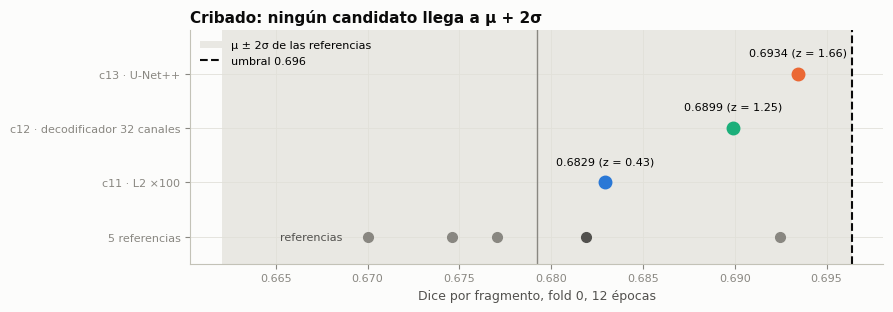

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axvspan(mu - 2 * sd, mu + 2 * sd, color=GRID, alpha=0.7, lw=0, label="μ ± 2σ de las referencias")
ax.axvline(mu, color=MUTED, lw=1)
ax.axvline(umbral, color=INK, lw=1.5, ls="--", label=f"umbral {umbral:.3f}")
for i, (k, r) in enumerate(R.iterrows()):
    ax.plot(r.dice_fragmento, -1, "o", color=INK2 if k.startswith("s11") else MUTED, ms=7)
ax.text(R.dice_fragmento.min() - 0.001, -1, "referencias  ", ha="right", va="center", fontsize=8, color=INK2)
for i, k in enumerate(CAND):
    ax.plot(T.loc[k, "Dice frag"], i, "o", color=COL[k], ms=9)
    ax.text(T.loc[k, "Dice frag"], i + 0.3, f"{T.loc[k, 'Dice frag']:.4f} (z = {T.loc[k, 'z']:.2f})", ha="center", va="bottom", fontsize=8)
ax.set_yticks([-1, 0, 1, 2], ["5 referencias", *[CORR[k] for k in CAND]])
ax.set_xlabel("Dice por fragmento, fold 0, 12 épocas")
ax.set_title("Cribado: ningún candidato llega a μ + 2σ", loc="left")
ax.set_ylim(-1.5, 2.8)
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "cribado")
plt.show()

- **Ninguno pasa.** Los tres superan el IoU medio de las referencias, pero ninguno el umbral de Dice 0,6964. El más cerca es U-Net++ (0,6934, z = 1,66, a 0,003 del umbral); L2 ×100 queda en z = 0,43.
- **Contra la semilla 42**, la referencia más alta (0,6925), U-Net++ gana por 0,0009 y los otros dos pierden. Las diferencias son del tamaño del ruido de semilla (σ ≈ 0,009).
- **Borde:** U-Net++ sube la precisión del borde a umbral 0,2 (0,43 contra 0,37 del control) con el mismo recall (0,157). El borde que marca es más limpio, pero sigue sin encontrar más superficie de fractura, y eso es lo que separaría los fragmentos en contacto.

## 4. Confirmación

In [8]:
if E2:
    display(pd.DataFrame(E2.get("candidatos", E2)))
else:
    print("No hubo etapa 2: ningún candidato pasó el cribado (etapa1.json · a_confirmar = []).")

No hubo etapa 2: ningún candidato pasó el cribado (etapa1.json · a_confirmar = []).


## 5. Modelo final y test

In [9]:
fin = read_json(REP / "fragments" / "v2_last_test_tuned.json")["global"]
print(f"Sin ganador: el modelo final sigue siendo v2_last + configs/tuned.yaml "
      f"(test: Dice por fragmento {fin['dice_fragmento']:.3f}, IoU {fin['iou_fragmento']:.3f}).")
print("El test no se volvió a medir esta semana.")

Sin ganador: el modelo final sigue siendo v2_last + configs/tuned.yaml (test: Dice por fragmento 0.768, IoU 0.697).
El test no se volvió a medir esta semana.


## 6. Lectura y decisión

- **Qué hicimos:** probamos tres remedios contra el sobreajuste de la cabeza de borde que no se habían probado: L2 ×100, un decodificador con la mitad de canales y un decodificador U-Net++ con supervisión profunda. Reglas fijadas antes de entrenar; control `s11_ref` para comprobar que el código nuevo no cambió el modelo base.
- **Qué salió:** ninguno pasó el cribado. Dice por fragmento 0,683 / 0,690 / 0,693 contra un umbral de 0,696 (μ 0,679, σ 0,009). Las curvas muestran el mismo patrón en los cuatro: la BCE de validación del borde tiene su mínimo en la época 0-1 y sube, mientras la de train baja.
- **Decisión:** los tres quedan **descartados con evidencia**, igual que `ftseg`. No hay confirmación, ni modelo nuevo, ni segunda medición de test. El modelo final sigue siendo `v2_last` + `configs/tuned.yaml`.
- **Lectura:** con estos tres, ya son nueve remedios estándar (regularizar, reducir, frenar, endurecer, cambiar la representación, añadir detalle fino) que no cierran la brecha. Es consistente con la hipótesis de la semana 11: el límite está en la etiqueta a 256 px (~1,3 mm por píxel), donde las grietas finas entre fragmentos en contacto no existen, y no en la capacidad ni en la regularización de la cabeza. U-Net++ deja una pista débil (borde más preciso, z = 1,66) que no alcanza para gastar 5 folds según la regla.